# Student Performance Prediction
**Course:** ELCE 455 Machine Learning with Python  
**Authors:** Abdulla Amangeldi, Merey Bolat  
**Dataset:** `StudentPerformanceFactors.csv` — 6,607 students, 19 input features, target `Exam_Score`

---

### What this notebook does
We treat academic performance as a **supervised regression** problem: predict a student’s final exam score from study habits, attendance, prior scores, and background factors (parental involvement, access to resources, motivation, and similar fields).

The workflow is linear:

1. **Inspect the data** — missing values, distributions, correlations, and how hours studied / resources relate to the score.
2. **Build a leak-free pipeline** — 60% train / 20% validation / 20% test, plus a `ColumnTransformer` (scale numbers, ordinal-encode ordered categories, one-hot-encode the rest).
3. **Fit models from the course** — dummy mean baseline, k-NN, linear / Ridge / Lasso, a shallow decision tree, then ensembles (AdaBoost, Random Forest, XGBoost) and an MLP.
4. **Select hyperparameters on validation data** — manual search plus `GridSearchCV` for Random Forest. The test set is used only at the end.
5. **Explain and export** — feature importance, actual vs predicted plot, saved figures and a `.pkl` model.
6. **At-risk classification (extra view)** — label students with `Exam_Score < 65` and report accuracy, precision, recall, and F1 with logistic regression (and by thresholding a regressor).

On this dataset the score is tightly concentrated and largely additive, so **Linear / Ridge regression** beat more flexible models on MAE, RMSE, and R². Ensembles are still included because they are required course topics, not because they are the most accurate here.

---

### Sections (what we actually implemented)

| Section | Week | What we did in this notebook |
|---|---|---|
| 1 | Week 1 | Defined the goal: predict `Exam_Score` and find drivers of performance for early intervention. |
| 2 | Week 2 | Imported libraries, fixed `SEED = 42`, auto-installed xgboost if missing, created `figures/` and `models/`. |
| 3 | Week 3 | Loaded the CSV; EDA with histograms, correlation heatmap, hours-vs-score scatter, and resource-access boxplot. |
| 4 | Week 4 | Split 60/20/20. Numeric / ordinal / nominal columns go through `ColumnTransformer` + `Pipeline`. |
| 5 | Week 5 | `KNeighborsRegressor` (k=7) trained on $S_{tr}$, scored on $S_{val}$. |
| 6 | Week 6 | Dummy mean baseline vs Linear, Ridge, and Lasso regression. |
| 7 | Week 7 | Midterm table: compared linear models and k-NN against the dummy on validation MAE / RMSE / R². |
| 8 | Week 8 | `DecisionTreeRegressor` (`max_depth=4`) and `plot_tree` visualization. |
| 9 | Week 9 | Ensembles: AdaBoost (stumps / shallow trees), Random Forest (bagging), XGBoost (gradient boosting). |
| 10 | Week 10 | Validation hyperparameter loop for AdaBoost; `GridSearchCV` (5-fold) for Random Forest on $S_{trval}$. |
| 11 | Week 11 | Random Forest feature importances (and permutation importance where used). |
| 12 | Week 12 | `MLPRegressor` as a small neural-network baseline. |
| 13 | Week 13 | Retrain on train+val, unbiased **test** comparison, save plots and `best_student_performance_model.pkl`, then at-risk metrics (accuracy / F1) with threshold 65. |

### Project Objective & Problem Statement
Academic success depends on a complex interplay of behavioral, socioeconomic, and institutional factors.
The goal of this project is to build a supervised regression model to predict a student's final exam score (`Exam_Score`)
and identify the key drivers of performance to enable early, data-driven educational interventions.

Initializing essential libraries, random seeds for 100% reproducibility, and directory structure.

In [2]:
from pathlib import Path
import subprocess
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Automatic check & installation of xgboost
try:
    import xgboost as xgb
    print("xgboost is already installed.")
except ImportError:
    print("xgboost is not installed. Installing now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    import xgboost as xgb
    print("xgboost installed successfully.")

# Scikit-Learn Modules matching syllabus topics
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# 1. Global Reproducibility & Styling
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300})

# 2. Dataset Filename and Cross-Platform Path Resolution
CSV_NAME = 'StudentPerformanceFactors.csv'
PROJECT_DIR = Path.cwd()

candidates = [
    PROJECT_DIR / CSV_NAME,
    PROJECT_DIR / 'data' / CSV_NAME,
    PROJECT_DIR.parent / CSV_NAME,
    Path('/content') / CSV_NAME,  # Google Colab default path
]

DATA_PATH = next((p for p in candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"'{CSV_NAME}' not found. Please place it in the notebook directory. "
        f"Searched paths: {[str(p) for p in candidates]}"
    )

FIGURES_DIR = PROJECT_DIR / 'figures'
MODELS_DIR = PROJECT_DIR / 'models'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f'Project root: {PROJECT_DIR}')
print(f'Data location: {DATA_PATH}')
print('Environment and directories successfully initialized.')


xgboost is already installed.
Project root: c:\Users\Мерей\Downloads\ELCE_455_Project
Data location: c:\Users\Мерей\Downloads\ELCE_455_Project\StudentPerformanceFactors.csv
Environment and directories successfully initialized.


## Week 3
Loading `StudentPerformanceFactors.csv` and inspecting raw features, missing values, duplicates, and target distributions.

In [3]:
# Load Dataset
df = pd.read_csv('StudentPerformanceFactors.csv')

print('Dataset Shape:', df.shape)
print('\n--- Head ---')
display(df.head())

print('\n--- Data Info ---')
display(df.info())

print('\n--- Descriptive Statistics ---')
display(df.describe(include='all').T)

# Check Missing Values & Duplicates
missing = df.isna().sum()
print('\n--- Missing Values ---')
print(missing[missing > 0])
print('\nDuplicate Rows:', df.duplicated().sum())

print('\n--- Target Summary (Exam_Score) ---')
print(df['Exam_Score'].describe())

Dataset Shape: (6607, 20)

--- Head ---


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  

None


--- Descriptive Statistics ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0



--- Missing Values ---
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate Rows: 0

--- Target Summary (Exam_Score) ---
count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64


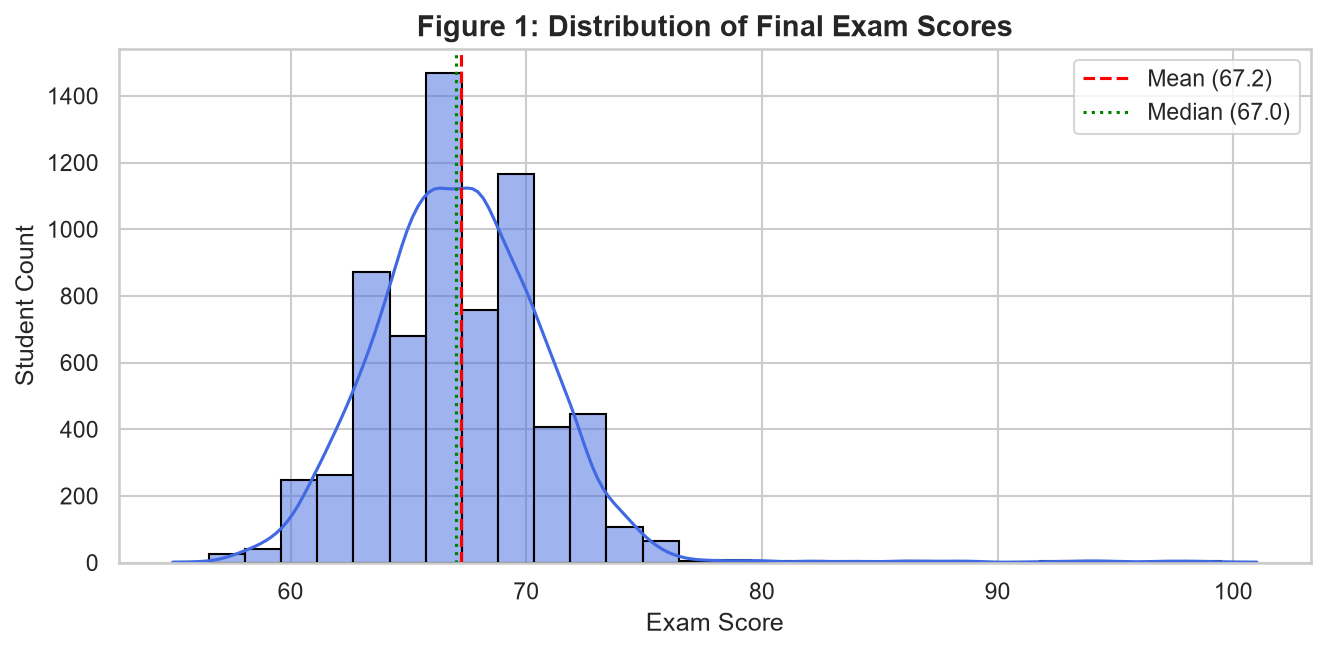

In [4]:
# EDA Plot 1: Target Variable Distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(df['Exam_Score'], kde=True, bins=30, color='royalblue', edgecolor='black')
plt.title('Figure 1: Distribution of Final Exam Scores', fontsize=14, fontweight='bold')
plt.xlabel('Exam Score')
plt.ylabel('Student Count')
plt.axvline(df['Exam_Score'].mean(), color='red', linestyle='--', label=f'Mean ({df["Exam_Score"].mean():.1f})')
plt.axvline(df['Exam_Score'].median(), color='green', linestyle=':', label=f'Median ({df["Exam_Score"].median():.1f})')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1_exam_score_dist.png')
plt.show()

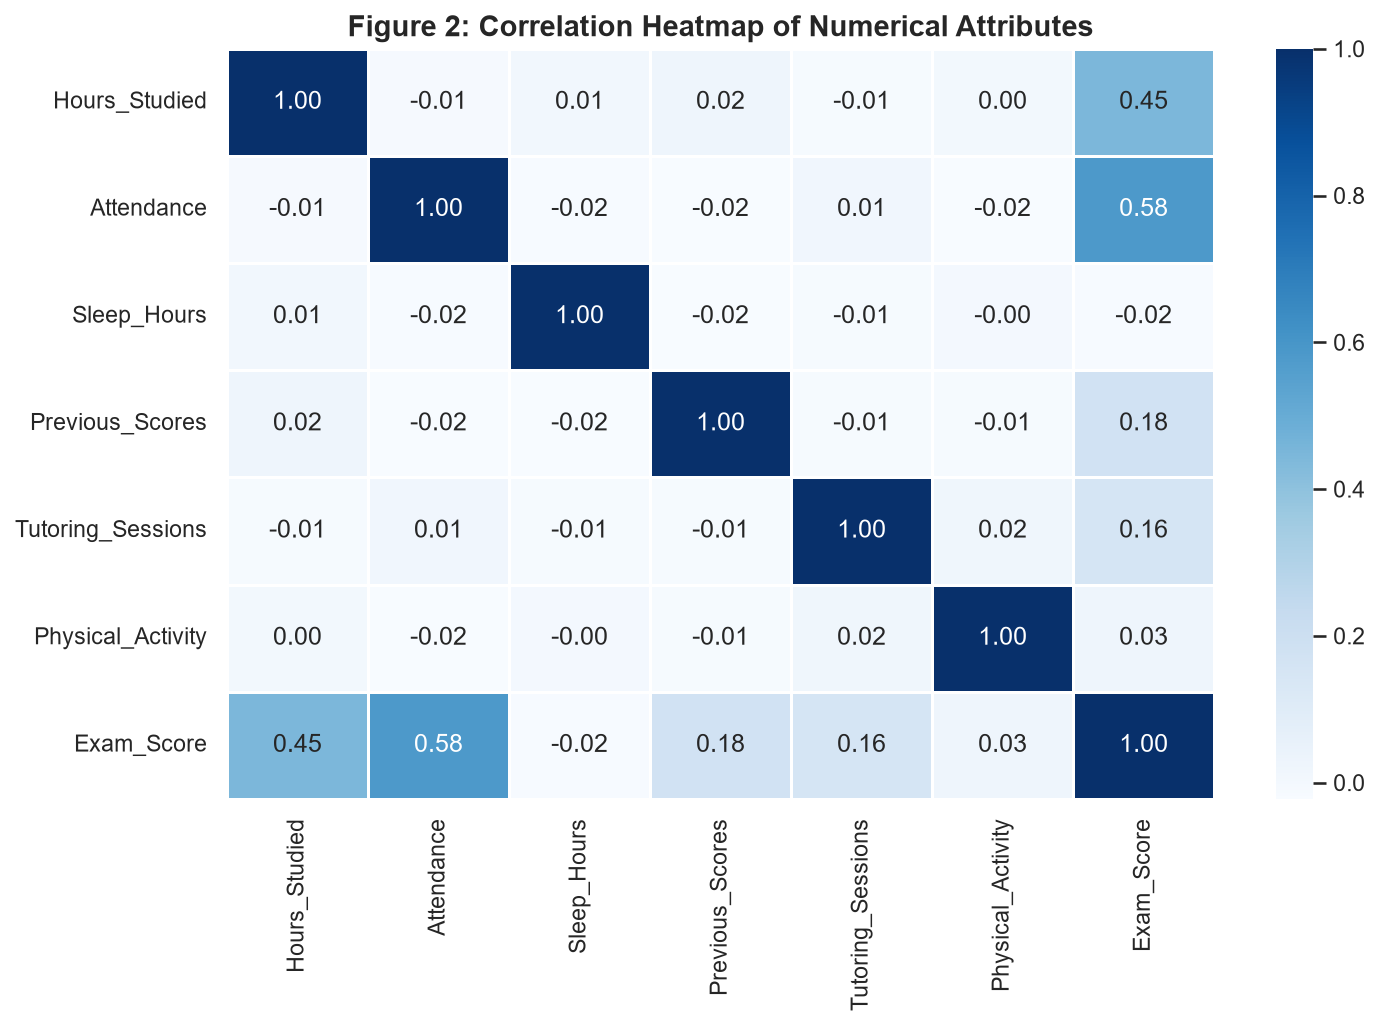

In [5]:
# EDA Plot 2: Correlation Heatmap for Numerical Features
num_cols_eda = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols_eda].corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Figure 2: Correlation Heatmap of Numerical Attributes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2_correlation_heatmap.png')
plt.show()

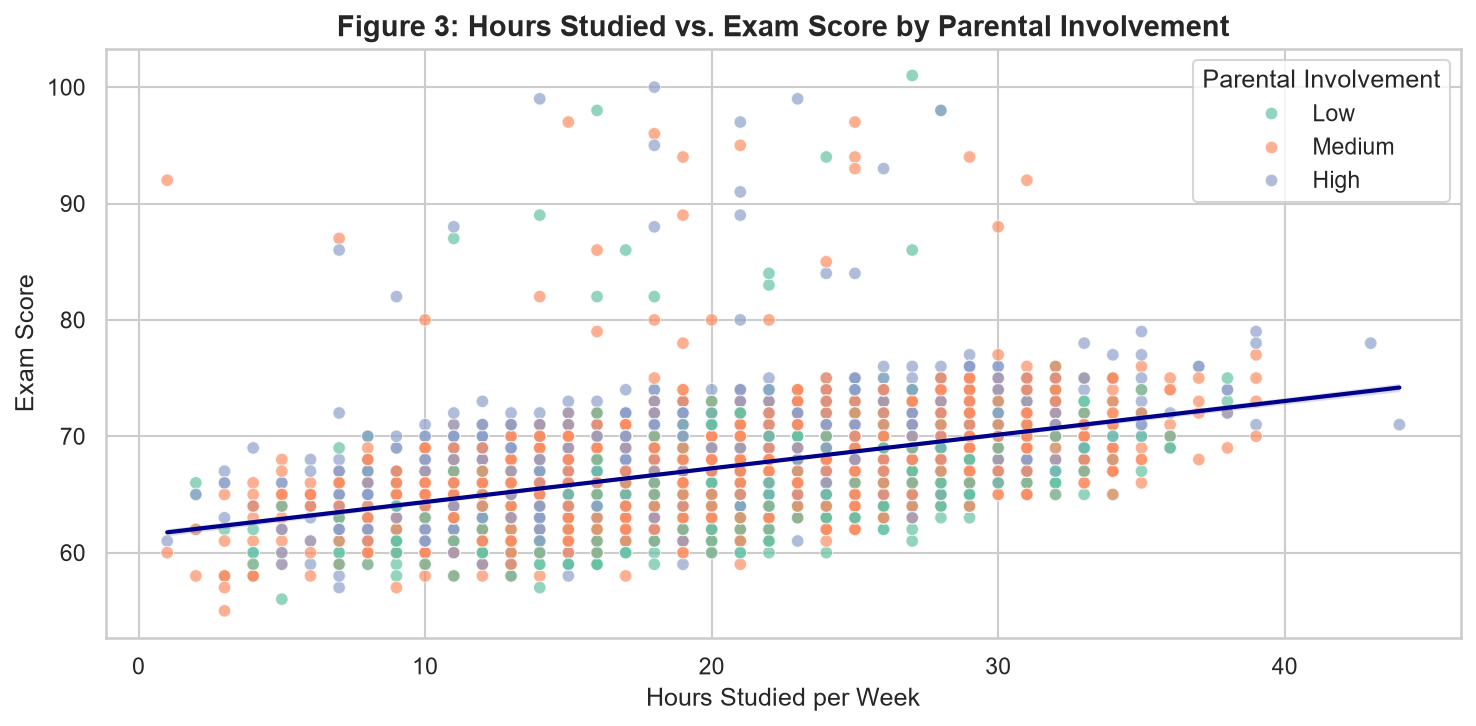

In [6]:
# EDA Plot 3: Scatter Plot of Hours Studied vs. Exam Score by Parental Involvement
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Hours_Studied', y='Exam_Score', hue='Parental_Involvement', palette='Set2', alpha=0.7)
sns.regplot(data=df, x='Hours_Studied', y='Exam_Score', scatter=False, color='darkblue', line_kws={'linewidth': 2})
plt.title('Figure 3: Hours Studied vs. Exam Score by Parental Involvement', fontsize=14, fontweight='bold')
plt.xlabel('Hours Studied per Week')
plt.ylabel('Exam Score')
plt.legend(title='Parental Involvement')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig3_hours_vs_score.png')
plt.show()

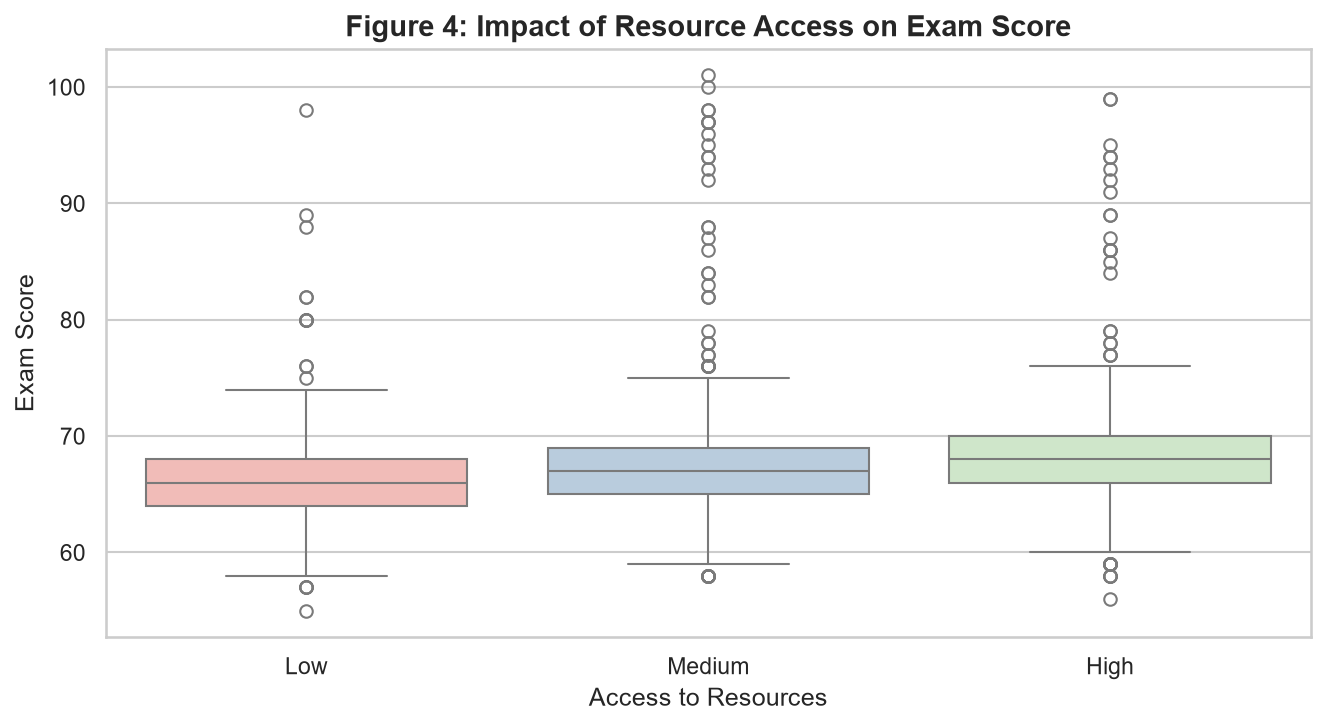

In [7]:
# EDA Plot 4: Boxplot of Exam Scores across Resource Access Categories
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Access_to_Resources', y='Exam_Score', order=['Low', 'Medium', 'High'], palette='Pastel1')
plt.title('Figure 4: Impact of Resource Access on Exam Score', fontsize=14, fontweight='bold')
plt.xlabel('Access to Resources')
plt.ylabel('Exam Score')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig4_resource_access_boxplot.png')
plt.show()

## Week 4
To strictly prevent **Data Leakage**, an explicit **3-Way Data Split** is performed:
- **Training Set ($S_{tr}$, 75%)
- **Validation Set ($S_{val}$, 15%)**
- **Test Set ($S_{te}$, 15%)**

`ColumnTransformer` preprocessing is defined and fitted ONLY on $S_{tr}$.

In [8]:
# Separate features and target
X = df.drop(columns=['Exam_Score'])
y = df['Exam_Score']

# Step 1: Hold out 15% for Final Unbiased Test Set (S_te)
X_trval, X_te, y_trval, y_te = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)

# Step 2: Split remaining 85% into Train (S_tr, 70% total) and Validation (S_val, 15% total)
# 0.15 / 0.85 ≈ 0.1765 of the remaining data = 15% of the full dataset
X_tr, X_val, y_tr, y_val = train_test_split(
    X_trval, y_trval, test_size=0.15 / 0.85, random_state=SEED
)

print(f'Train Set (|S_tr|): {X_tr.shape[0]} samples, {X_tr.shape[1]} features')
print(f'Val Set   (|S_val|): {X_val.shape[0]} samples, {X_val.shape[1]} features')
print(f'Test Set  (|S_te|):  {X_te.shape[0]} samples, {X_te.shape[1]} features')

# Categorize columns
num_cols = ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Sleep_Hours', 'Tutoring_Sessions', 'Physical_Activity']
ord_cols = ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Teacher_Quality', 'Family_Income']
nom_cols = [c for c in X.columns if c not in num_cols + ord_cols]

ord_categories = [
    ['Low', 'Medium', 'High'],  # Parental_Involvement
    ['Low', 'Medium', 'High'],  # Access_to_Resources
    ['Low', 'Medium', 'High'],  # Motivation_Level
    ['Low', 'Medium', 'High'],  # Teacher_Quality
    ['Low', 'Medium', 'High']   # Family_Income
]

# Build ColumnTransformer
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ord_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=ord_categories))
])

nom_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('ord', ord_pipeline, ord_cols),
        ('nom', nom_pipeline, nom_cols)
    ]
)
print('ColumnTransformer pipeline defined successfully.')

Train Set (|S_tr|): 4624 samples, 19 features
Val Set   (|S_val|): 991 samples, 19 features
Test Set  (|S_te|):  992 samples, 19 features
ColumnTransformer pipeline defined successfully.


## Week 5: k-Nearest Neighbors
Implementing `KNeighborsRegressor` inside a scikit-learn Pipeline, trained on $S_{tr}$ and evaluated on $S_{val}$.

In [9]:
knn_pipe = Pipeline([
    ('prep', preprocessor),
    ('regressor', KNeighborsRegressor(n_neighbors=7))
])

# Fit on S_tr
knn_pipe.fit(X_tr, y_tr)

# Evaluate on Validation Set (S_val)
y_val_pred_knn = knn_pipe.predict(X_val)
knn_val_mae = mean_absolute_error(y_val, y_val_pred_knn)
knn_val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_knn))
knn_val_r2 = r2_score(y_val, y_val_pred_knn)

print(f'k-NN (k=7) Validation MAE:  {knn_val_mae:.4f}')
print(f'k-NN (k=7) Validation RMSE: {knn_val_rmse:.4f}')
print(f'k-NN (k=7) Validation R2:   {knn_val_r2:.4f}')

k-NN (k=7) Validation MAE:  1.3112
k-NN (k=7) Validation RMSE: 2.4011
k-NN (k=7) Validation R2:   0.5881


## Linear Models (Week 6)
Evaluating linear regression baselines on $S_{tr}$ and $S_{val}$: Baseline Mean Regressor, Ordinary Least Squares (Linear Regression), Ridge Regression (L2), and Lasso Regression (L1).

In [10]:
# 1. Baseline Mean Regressor
dummy_pipe = Pipeline([('prep', preprocessor), ('regressor', DummyRegressor(strategy='mean'))])
dummy_pipe.fit(X_tr, y_tr)
y_val_dummy = dummy_pipe.predict(X_val)

# 2. Linear Regression
lr_pipe = Pipeline([('prep', preprocessor), ('regressor', LinearRegression())])
lr_pipe.fit(X_tr, y_tr)
y_val_lr = lr_pipe.predict(X_val)

# 3. Ridge Regression
ridge_pipe = Pipeline([('prep', preprocessor), ('regressor', Ridge(alpha=1.0))])
ridge_pipe.fit(X_tr, y_tr)
y_val_ridge = ridge_pipe.predict(X_val)

# 4. Lasso Regression
lasso_pipe = Pipeline([('prep', preprocessor), ('regressor', Lasso(alpha=0.1))])
lasso_pipe.fit(X_tr, y_tr)
y_val_lasso = lasso_pipe.predict(X_val)

print(f'Dummy Baseline Validation R2:  {r2_score(y_val, y_val_dummy):.4f}')
print(f'Linear Regression Validation R2:{r2_score(y_val, y_val_lr):.4f}')
print(f'Ridge Regression Validation R2: {r2_score(y_val, y_val_ridge):.4f}')
print(f'Lasso Regression Validation R2: {r2_score(y_val, y_val_lasso):.4f}')

Dummy Baseline Validation R2:  -0.0001
Linear Regression Validation R2:0.7607
Ridge Regression Validation R2: 0.7607
Lasso Regression Validation R2: 0.7185


Comparing simple linear models and k-NN against the Dummy Baseline on the Validation Set ($S_{val}$).

In [11]:
midterm_df = pd.DataFrame([
    {'Model': 'Dummy (Mean Baseline)', 'Val MAE': mean_absolute_error(y_val, y_val_dummy), 'Val RMSE': np.sqrt(mean_squared_error(y_val, y_val_dummy)), 'Val R2': r2_score(y_val, y_val_dummy)},
    {'Model': 'k-NN (k=7)', 'Val MAE': knn_val_mae, 'Val RMSE': knn_val_rmse, 'Val R2': knn_val_r2},
    {'Model': 'Linear Regression', 'Val MAE': mean_absolute_error(y_val, y_val_lr), 'Val RMSE': np.sqrt(mean_squared_error(y_val, y_val_lr)), 'Val R2': r2_score(y_val, y_val_lr)},
    {'Model': 'Ridge Regression', 'Val MAE': mean_absolute_error(y_val, y_val_ridge), 'Val RMSE': np.sqrt(mean_squared_error(y_val, y_val_ridge)), 'Val R2': r2_score(y_val, y_val_ridge)},
    {'Model': 'Lasso Regression', 'Val MAE': mean_absolute_error(y_val, y_val_lasso), 'Val RMSE': np.sqrt(mean_squared_error(y_val, y_val_lasso)), 'Val R2': r2_score(y_val, y_val_lasso)}
])
display(midterm_df)

,Model,Val MAE,Val RMSE,Val R2
0,Dummy (Mean Baseline),2.703243,3.741408,-0.000053
1,k-NN (k=7),1.311230,2.401142,0.588103
2,Linear Regression,0.455170,1.830073,0.760729
3,Ridge Regression,0.455257,1.830179,0.760701
4,Lasso Regression,0.743086,1.984909,0.718529


## Week 8
Implementing `DecisionTreeRegressor` and visualizing decision rules using `plot_tree` from `sklearn.tree`.

Decision Tree (max_depth=4) Validation R2: 0.4937, RMSE: 2.662


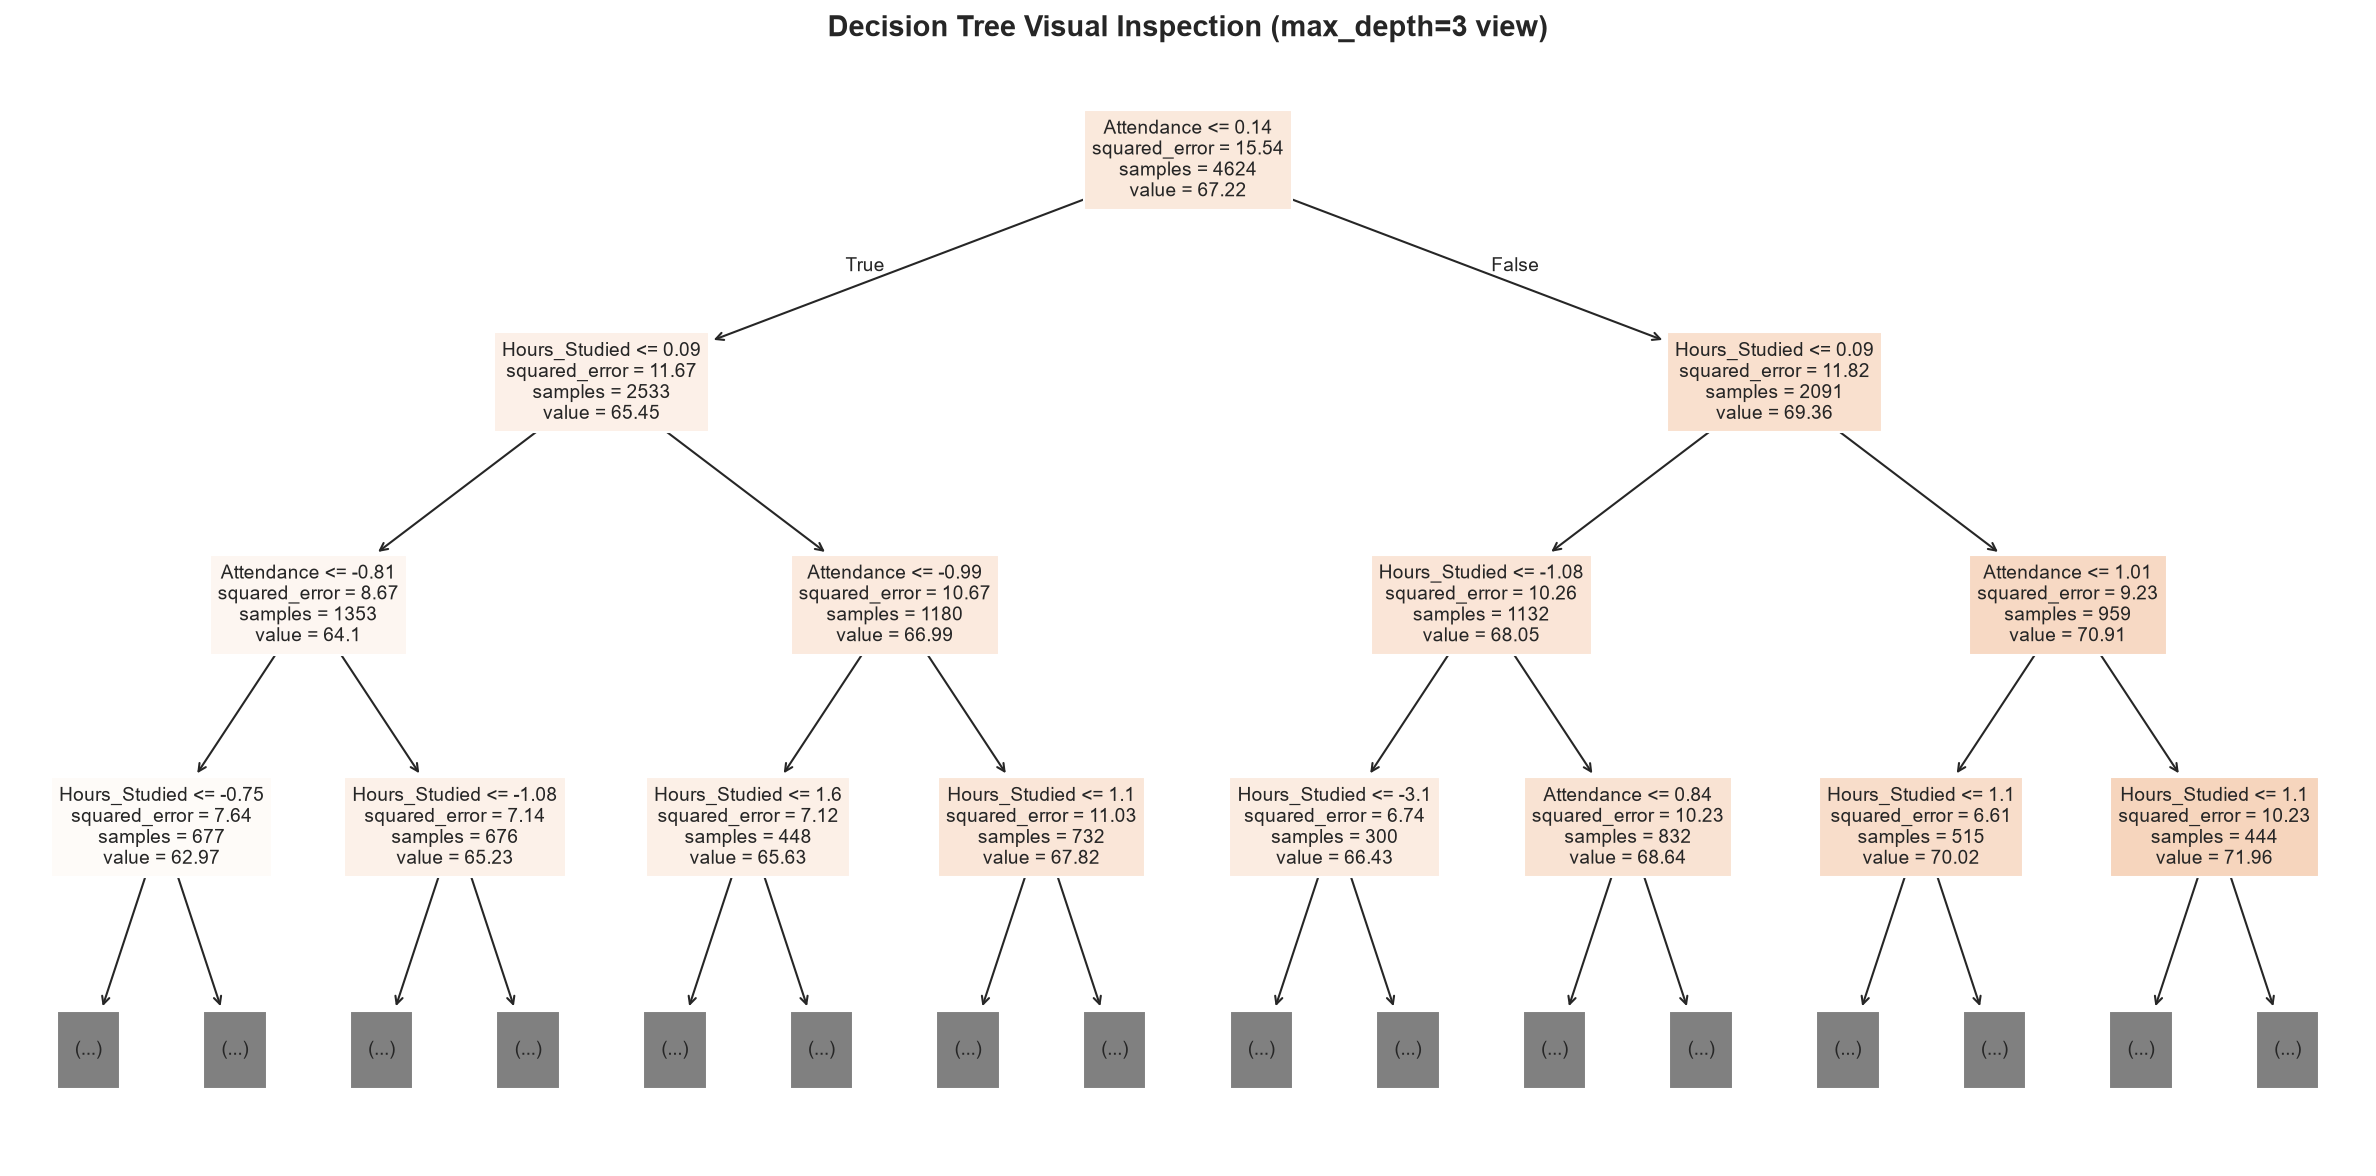

In [12]:
# Fit Decision Tree on S_tr
dt_pipe = Pipeline([
    ('prep', preprocessor),
    ('regressor', DecisionTreeRegressor(max_depth=4, random_state=SEED))
])
dt_pipe.fit(X_tr, y_tr)
y_val_dt = dt_pipe.predict(X_val)

print(f'Decision Tree (max_depth=4) Validation R2: {r2_score(y_val, y_val_dt):.4f}, RMSE: {np.sqrt(mean_squared_error(y_val, y_val_dt)):.3f}')

# Visualize Tree structure using plot_tree
dt_model = dt_pipe.named_steps['regressor']
nom_encoder = dt_pipe.named_steps['prep'].named_transformers_['nom'].named_steps['encoder']
encoded_nom_cols = list(nom_encoder.get_feature_names_out(nom_cols))
all_feature_names = num_cols + ord_cols + encoded_nom_cols

plt.figure(figsize=(16, 8))
plot_tree(dt_model, feature_names=all_feature_names, filled=True, max_depth=3, fontsize=9, precision=2)
plt.title('Decision Tree Visual Inspection (max_depth=3 view)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_decision_tree_structure.png')
plt.show()

## Ensemble Learning (Week 9)
Implementing Ensemble methods:
- **AdaBoostRegressor** (`AdaBoost.R2` formulation from lecture with decision stump base estimator and learning rate $\eta$);
- **RandomForestRegressor** (Bagging);
- **XGBoostRegressor** (Gradient Boosting).

In [13]:
# 1. AdaBoost Regressor (AdaBoost.R2 formulation)
base_stump = DecisionTreeRegressor(max_depth=3, random_state=SEED)
adaboost_pipe = Pipeline([
    ('prep', preprocessor),
    ('regressor', AdaBoostRegressor(estimator=base_stump, n_estimators=50, learning_rate=1.0, random_state=SEED))
])
adaboost_pipe.fit(X_tr, y_tr)
y_val_ada = adaboost_pipe.predict(X_val)

# 2. Random Forest Regressor
rf_pipe = Pipeline([
    ('prep', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=150, max_depth=10, random_state=SEED, n_jobs=-1))
])
rf_pipe.fit(X_tr, y_tr)
y_val_rf = rf_pipe.predict(X_val)

# 3. XGBoost Regressor
xgb_pipe = Pipeline([
    ('prep', preprocessor),
    ('regressor', xgb.XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=SEED, n_jobs=-1))
])
xgb_pipe.fit(X_tr, y_tr)
y_val_xgb = xgb_pipe.predict(X_val)

print(f'AdaBoost (n_est=50, lr=1.0) Validation R2: {r2_score(y_val, y_val_ada):.4f}, RMSE: {np.sqrt(mean_squared_error(y_val, y_val_ada)):.3f}')
print(f'Random Forest Validation R2:              {r2_score(y_val, y_val_rf):.4f}, RMSE: {np.sqrt(mean_squared_error(y_val, y_val_rf)):.3f}')
print(f'XGBoost Validation R2:                    {r2_score(y_val, y_val_xgb):.4f}, RMSE: {np.sqrt(mean_squared_error(y_val, y_val_xgb)):.3f}')

AdaBoost (n_est=50, lr=1.0) Validation R2: -1.5823, RMSE: 6.012
Random Forest Validation R2:              0.6523, RMSE: 2.206
XGBoost Validation R2:                    0.7101, RMSE: 2.014


## Week 10
Demonstrating both evaluation approaches:
1. **Manual Validation `search_space` Loop** (training on $S_{tr}$ and evaluating on $S_{val}$ as shown in lectures).
2. **GridSearchCV with 5-Fold Cross-Validation** on $S_{trval}$ ($S_{tr} \cup S_{val}$).

In [14]:
# --- Part 1: Lecture-style Search Space Loop on S_tr vs S_val ---
search_space = {
    'KNN':     (KNeighborsRegressor, [{'n_neighbors': k} for k in [3, 5, 7, 9]]),
    'Ridge':   (Ridge,               [{'alpha': a} for a in [0.01, 0.1, 1.0, 10.0]]),
    'AdaBoost':(AdaBoostRegressor,  [{'n_estimators': m, 'learning_rate': lr} for m in [30, 50] for lr in [0.1, 1.0]])
}

best_name, best_theta, best_score = None, None, -np.inf
for name, (Algorithm, H) in search_space.items():
    for theta in H:
        model_pipe = Pipeline([
            ('prep', preprocessor),
            ('regressor', Algorithm(**theta))
        ]).fit(X_tr, y_tr)
        
        score = model_pipe.score(X_val, y_val)
        print(f'{name:10s} {str(theta):45s} Validation R2 = {score:.4f}')
        if score > best_score:
            best_name, best_theta, best_score = name, theta, score

print(f'\nBest Search Space Combination: {best_name} with {best_theta} (Val R2 = {best_score:.4f})\n')

# --- Part 2: Systematic GridSearchCV with 5-Fold Cross-Validation ---
param_grid_rf = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [8, 12, None],
    'regressor__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(rf_pipe, param_grid_rf, cv=5, scoring='r2', n_jobs=-1)
grid_rf.fit(X_trval, y_trval)

best_rf_model = grid_rf.best_estimator_
y_te_best_rf = best_rf_model.predict(X_te)

print('Best GridSearchCV Hyperparameters:', grid_rf.best_params_)
print(f'Tuned Random Forest Test R2:   {r2_score(y_te, y_te_best_rf):.4f}')
print(f'Tuned Random Forest Test RMSE: {np.sqrt(mean_squared_error(y_te, y_te_best_rf)):.3f}')

KNN        {'n_neighbors': 3}                            Validation R2 = 0.5037
KNN        {'n_neighbors': 5}                            Validation R2 = 0.5549
KNN        {'n_neighbors': 7}                            Validation R2 = 0.5881
KNN        {'n_neighbors': 9}                            Validation R2 = 0.6026
Ridge      {'alpha': 0.01}                               Validation R2 = 0.7607
Ridge      {'alpha': 0.1}                                Validation R2 = 0.7607
Ridge      {'alpha': 1.0}                                Validation R2 = 0.7607
Ridge      {'alpha': 10.0}                               Validation R2 = 0.7604
AdaBoost   {'n_estimators': 30, 'learning_rate': 0.1}    Validation R2 = 0.4074
AdaBoost   {'n_estimators': 30, 'learning_rate': 1.0}    Validation R2 = -0.6811
AdaBoost   {'n_estimators': 50, 'learning_rate': 0.1}    Validation R2 = 0.3700
AdaBoost   {'n_estimators': 50, 'learning_rate': 1.0}    Validation R2 = -1.6052

Best Search Space Combination: Ridge 

## Feature Selection & Model Explainability (Week 11)
Extracting feature importances from the tuned Random Forest model to rank the primary factors driving student performance.

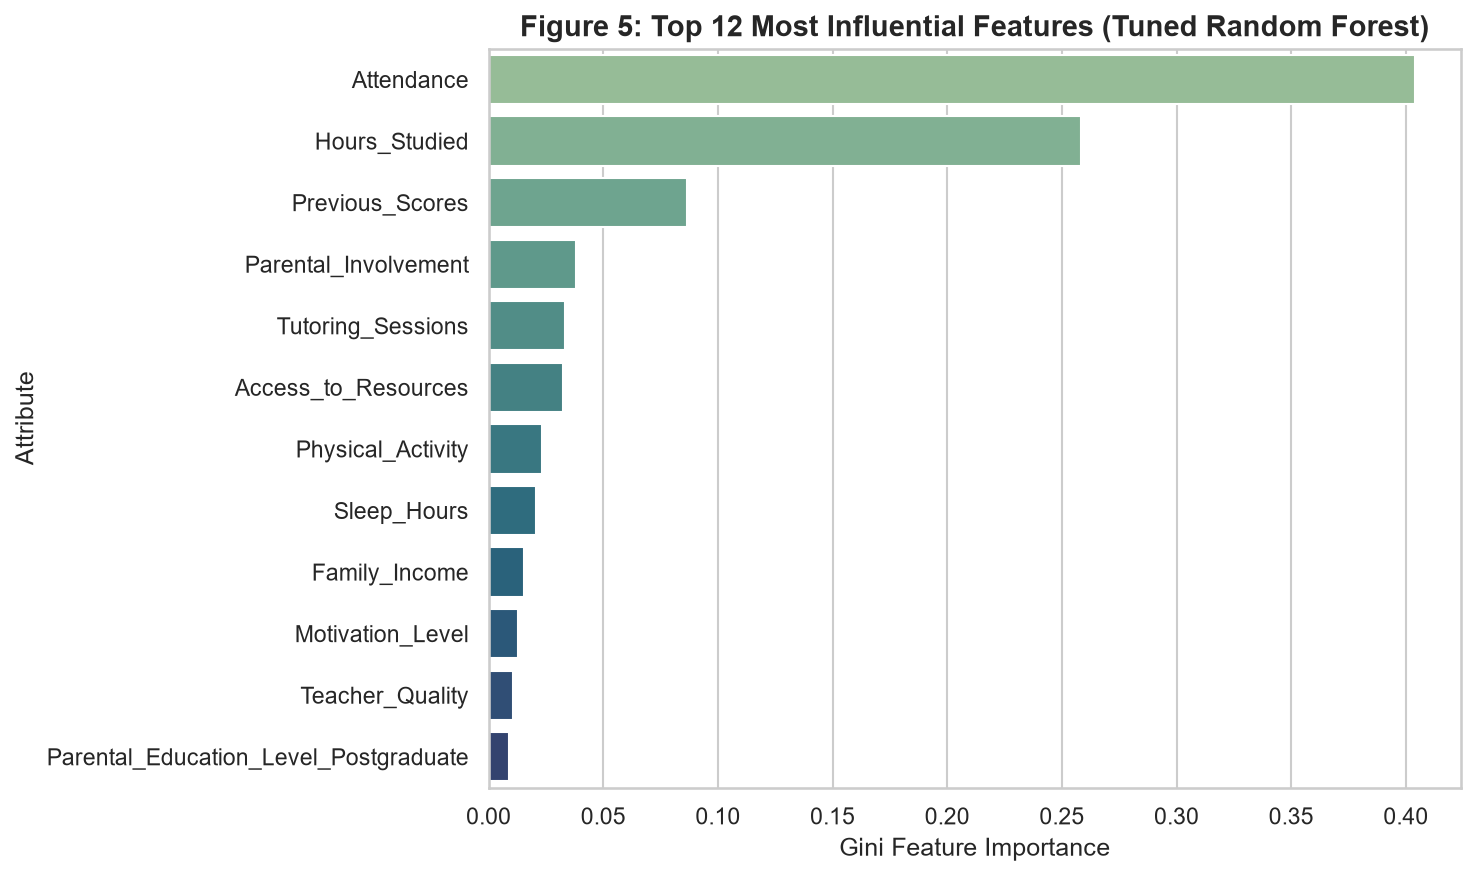

In [15]:
# Extract transformed feature names
nom_encoder = best_rf_model.named_steps['prep'].named_transformers_['nom'].named_steps['encoder']
encoded_nom_cols = list(nom_encoder.get_feature_names_out(nom_cols))
all_feature_names = num_cols + ord_cols + encoded_nom_cols

# Feature Importance
importances = best_rf_model.named_steps['regressor'].feature_importances_
feat_imp_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plot Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(12), x='Importance', y='Feature', palette='crest')
plt.title('Figure 5: Top 12 Most Influential Features (Tuned Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Gini Feature Importance')
plt.ylabel('Attribute')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig5_feature_importance.png')
plt.show()

## Week 12
Evaluating a Multi-Layer Perceptron (`MLPRegressor`) neural network as a deep learning baseline.

In [16]:
mlp_pipe = Pipeline([
    ('prep', preprocessor),
    ('regressor', MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, random_state=SEED))
])
mlp_pipe.fit(X_tr, y_tr)
y_val_mlp = mlp_pipe.predict(X_val)

print(f'MLP Neural Net Validation R2:   {r2_score(y_val, y_val_mlp):.4f}')
print(f'MLP Neural Net Validation RMSE: {np.sqrt(mean_squared_error(y_val, y_val_mlp)):.3f}')

MLP Neural Net Validation R2:   0.7378
MLP Neural Net Validation RMSE: 1.916


## Week 13
Retraining top models on combined Training+Validation data ($S_{trval}$) and evaluating final unbiased performance on Test Set ($S_{te}$).

,Model,Test MAE,Test RMSE,Test R2
0,Linear Regression,0.442374,1.704593,0.797636
1,Ridge Regression,0.442444,1.704643,0.797624
2,Lasso Regression,0.751150,1.838417,0.764614
3,XGBoost Regressor,0.809064,1.899143,0.748807
4,MLP Neural Network,0.927437,1.915156,0.744554
5,Tuned Random Forest (Best),1.060856,2.065424,0.702895
6,k-NN (k=7),1.295363,2.255812,0.645597
7,Decision Tree (max_depth=4),1.650736,2.532324,0.553388
8,Dummy Baseline (Mean),2.839650,3.790226,-0.000511
9,AdaBoost Regressor,3.850184,4.789106,-0.597352


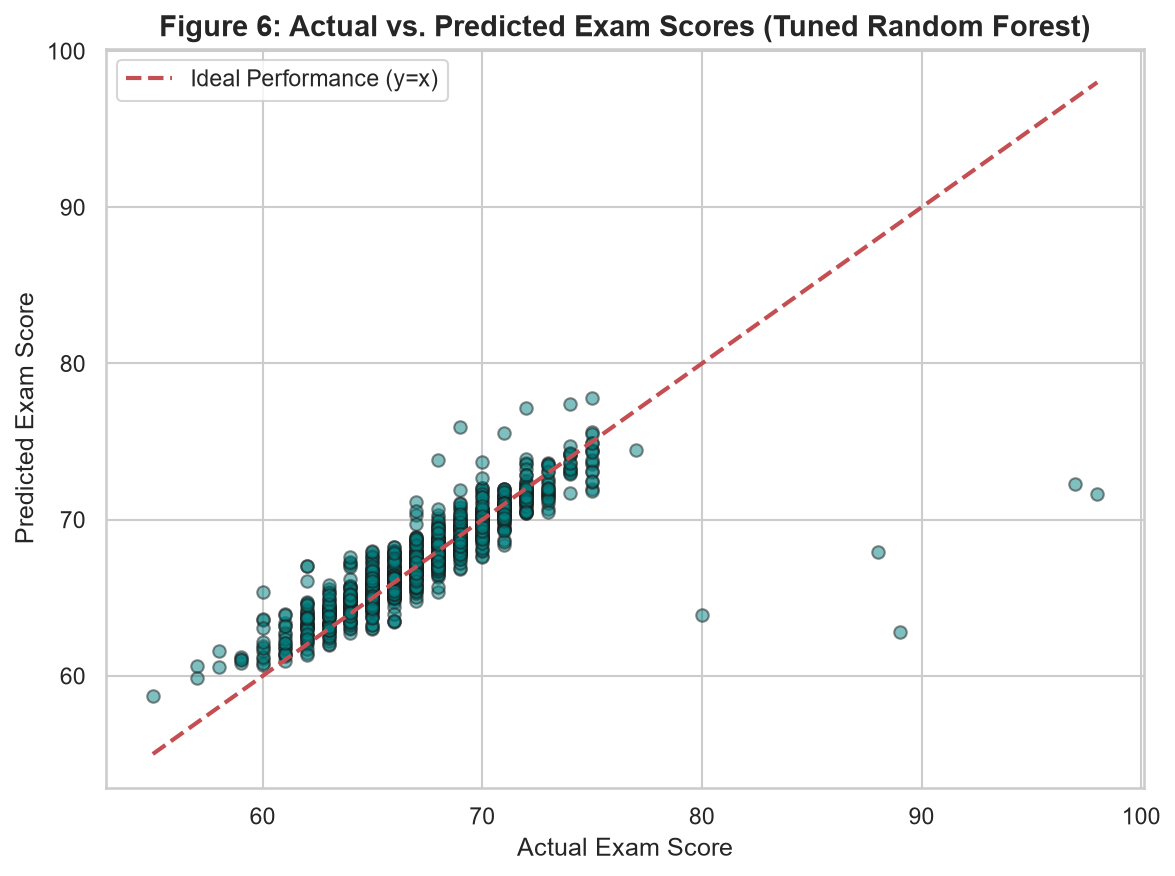

Best performing model saved to c:\Users\Мерей\Downloads\ELCE_455_Project\models\best_student_performance_model.pkl


In [17]:
# Retrain all pipelines on S_trval and predict on S_te
models_dict = {
    'Dummy Baseline (Mean)': dummy_pipe,
    'k-NN (k=7)': knn_pipe,
    'Linear Regression': lr_pipe,
    'Ridge Regression': ridge_pipe,
    'Lasso Regression': lasso_pipe,
    'Decision Tree (max_depth=4)': dt_pipe,
    'AdaBoost Regressor': adaboost_pipe,
    'XGBoost Regressor': xgb_pipe,
    'MLP Neural Network': mlp_pipe
}

final_results = []
for name, model in models_dict.items():
    model.fit(X_trval, y_trval)
    y_te_pred = model.predict(X_te)
    final_results.append({
        'Model': name,
        'Test MAE': mean_absolute_error(y_te, y_te_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_te, y_te_pred)),
        'Test R2': r2_score(y_te, y_te_pred)
    })

# Add Tuned Random Forest
final_results.append({
    'Model': 'Tuned Random Forest (Best)',
    'Test MAE': mean_absolute_error(y_te, y_te_best_rf),
    'Test RMSE': np.sqrt(mean_squared_error(y_te, y_te_best_rf)),
    'Test R2': r2_score(y_te, y_te_best_rf)
})

final_summary_df = pd.DataFrame(final_results).sort_values(by='Test R2', ascending=False).reset_index(drop=True)
display(final_summary_df)

# Diagnostic Plot: Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_te, y_te_best_rf, alpha=0.5, color='teal', edgecolors='k')
plt.plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], 'r--', linewidth=2, label='Ideal Performance (y=x)')
plt.title('Figure 6: Actual vs. Predicted Exam Scores (Tuned Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig6_actual_vs_predicted.png')
plt.show()

# Export Best Model Artifact
best_model_path = MODELS_DIR / 'best_student_performance_model.pkl'
joblib.dump(best_rf_model, best_model_path)
print(f'Best performing model saved to {best_model_path}')

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

THRESHOLD = 65  # At-risk vs not at-risk
y_true_cls = (y_te < THRESHOLD).astype(int)   # 1 = at risk (positive class)

In [19]:
y_pred_cls = (y_te_pred < THRESHOLD).astype(int)

acc  = accuracy_score(y_true_cls, y_pred_cls)
prec = precision_score(y_true_cls, y_pred_cls, zero_division=0)
rec  = recall_score(y_true_cls, y_pred_cls, zero_division=0)
f1   = f1_score(y_true_cls, y_pred_cls, zero_division=0)

In [20]:
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso

y_trval_cls = (y_trval < THRESHOLD).astype(int)
y_te_cls    = (y_te < THRESHOLD).astype(int)

log_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))
])
log_pipe.fit(X_trval, y_trval_cls)
y_hat = log_pipe.predict(X_te)

print('Accuracy:', accuracy_score(y_te_cls, y_hat))
print('Precision:', precision_score(y_te_cls, y_hat))
print('Recall:', recall_score(y_te_cls, y_hat))
print('F1:', f1_score(y_te_cls, y_hat))
print(classification_report(y_te_cls, y_hat, target_names=['Not at risk', 'At risk']))
print(confusion_matrix(y_te_cls, y_hat))

# if we put the threshold the result will differ
print('Regressor-as-classifier (threshold = 65)')
print('Accuracy:', acc)
print('Precision:', prec)
print('Recall:', rec)
print('F1:', f1)

Accuracy: 0.9707661290322581
Precision: 0.875
Recall: 1.0
F1: 0.9333333333333333
              precision    recall  f1-score   support

 Not at risk       1.00      0.96      0.98       789
     At risk       0.88      1.00      0.93       203

    accuracy                           0.97       992
   macro avg       0.94      0.98      0.96       992
weighted avg       0.97      0.97      0.97       992

[[760  29]
 [  0 203]]
Regressor-as-classifier (threshold = 65)
Accuracy: 0.9737903225806451
Precision: 0.9682539682539683
Recall: 0.9014778325123153
F1: 0.9336734693877551


In [21]:
cm = confusion_matrix(y_te_cls, y_hat, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

if fn == 0:
    print(
        f"On the test set, the classifier identified all {tp} at-risk students "
        f"(Exam_Score < {THRESHOLD}). It missed no at-risk students, "
        f"but incorrectly flagged {fp} students as at risk."
    )
else:
    print(
        f"On the test set, the classifier identified {tp} at-risk students "
        f"and missed {fn}. It incorrectly flagged {fp} students as at risk."
    )

On the test set, the classifier identified all 203 at-risk students (Exam_Score < 65). It missed no at-risk students, but incorrectly flagged 29 students as at risk.


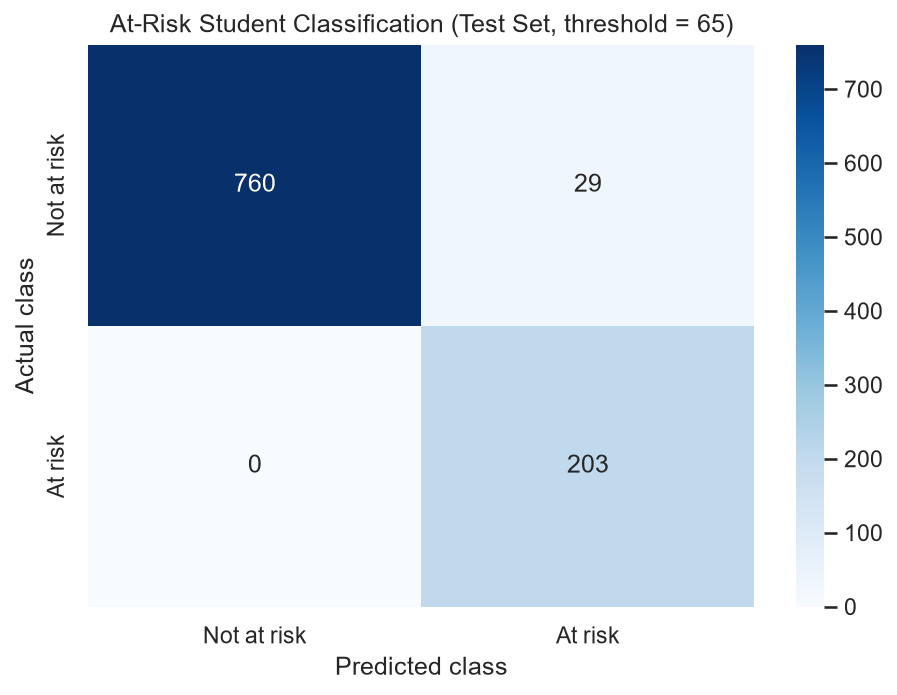

In [22]:
cm = confusion_matrix(y_te_cls, y_hat, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not at risk", "At risk"],
    yticklabels=["Not at risk", "At risk"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("At-Risk Student Classification (Test Set, threshold = 65)")
plt.tight_layout()
plt.show()